# Time evolution

In [601]:
from QuantumCompiling import CircuitState,CircuitShape
import scipy.sparse as sp
import numpy as np
import csv
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

Si implementa il metodo simulate della classe CircuitOperation per simulare l'ottimizzazione di un circuito

In [602]:
class CircuitOperations:
    def __init__(self,shape):  
        self._shape = shape
        self._hops = np.zeros((len(shape._steps),len(shape._steps)),dtype=object)
        self._Hd = None
        self._Hi = None
        for i in range(len(shape._steps)):
            for j in range(len(shape._steps)):
                self._hops[i,j] = sp.csr_matrix( np.kron(
                    np.conj(shape.state_of_step(shape._steps[j])).reshape(-1,1),
                    shape.state_of_step(shape._steps[i])
                ), dtype='complex')

    # moves the single-step-circuit state to "to" single-step-circuit state
    def hop(self,to,circuit):
        if not circuit.get_n_steps() == 1: raise Exception("The circuit is not single-step")
        circuit._state = self._hops[circuit._shape.index_of_state(circuit._state),to].dot(circuit._state) 
        
    def get_H_eps(self,ids1,ids2,n_steps):
        id = sp.identity(len(self._hops), format='csr')
        H_eps = sp.csr_matrix((len(self._hops)**n_steps,len(self._hops)**n_steps), dtype='complex')
        for i_eq in range(0,n_steps+1-len(ids1)):
            H_eps_i = sp.identity(1,format='csr') 
            for i in range(0,i_eq):
                H_eps_i = sp.kron(H_eps_i,id)
            for i in range(0,len(ids1)):
                H_eps_i = sp.kron(H_eps_i,self._hops[ids1[i],ids2[i]])
            for i in range(i_eq+len(ids1),n_steps):
                H_eps_i = sp.kron(H_eps_i,id)
            H_eps += H_eps_i
        
        return H_eps + H_eps.getH()
    
    def get_Hd(self, dmax, n_steps):
        Hd = sp.csr_matrix((len(self._hops)**n_steps,len(self._hops)**n_steps), dtype='complex')
        for d in range(2,dmax+1):
            filename = f"{self._shape._eq_dir}/eq_d={d}.csv"
            with open(filename, 'r', newline='') as fin:
                reader = csv.reader(fin, delimiter="\t")
                #skips the header
                row = None
                while(row != "equivalences:"):
                    row = next(reader)[0]
                
                for row in reader:
                    ids1 = [int(id) for id in row[:d]]
                    ids2 = [int(id) for id in row[d:]]
                    Hd += self.get_H_eps(ids1,ids2,n_steps)
        return Hd
    
    def get_Hi(self, n_steps):
        if self._shape._infidelities is None: raise Exception("infidelities not provided in shape's constructor")
        Hi_step = sp.csr_matrix((self._shape.get_n_steps(),self._shape.get_n_steps()), dtype='complex')
        for i in range(self._shape.get_n_steps()):
            Hi_step += self._shape._infidelities[i] * self._hops[i,i]
        
        id = sp.identity(self._shape.get_n_steps(), format='csr')
        Hi= sp.csr_matrix((self._shape.get_n_steps()**n_steps,self._shape.get_n_steps()**n_steps), dtype='complex')
        for i in range(n_steps):
            Hi_i = sp.identity(1,format='csr') 
            for _ in range(0,i):
                Hi_i = sp.kron(Hi_i,id)
            Hi_i = sp.kron(Hi_i,Hi_step)
            for _ in range(0,n_steps-i-1):
                Hi_i = sp.kron(Hi_i,id)
            Hi+= Hi_i
        
        return Hi
    
    def multiply(operator,circuit_state):
        final_state = operator.dot(circuit_state._state)
        return CircuitState(circuit_state._shape,state=final_state)

    def expected_value_from_state(operator, state):
        return np.vdot(state,operator.dot(state))
    def dev_std_from_state(operator,state):
        return np.sqrt( np.vdot(state, operator.dot(operator).dot(state)) - np.vdot(state,operator.dot(state))**2 )
        
    def expected_value(operator,circuit_state):
        return CircuitOperations.expected_value_from_state(operator, circuit_state._state)
    def dev_std(operator, circuit_state):
        return CircuitOperations.dev_std_from_state(operator, circuit_state._state)
    
    def normalize(state):
        return state/np.sqrt(sum(np.abs(state)**2))
    
    
    def infidelity(self,circuit_state):
        if self._Hi is None: raise Exception("Hamiltonians not loaded")
        return CircuitOperations.expected_value(self._Hi, circuit_state).real
    def load_H(self,dmax, n_steps):
        self._Hd = self.get_Hd(dmax,n_steps)
        self._Hi = self.get_Hi(n_steps)
    def delete_H():
        self._Hd = None
        self._Hi = None
        
    def simulate(self,circuit_state,Td=1,Nd=4,Ti=1,Ni=4):
        if self._Hd is None or self._Hi is None: raise Exception("Hamiltonians not loaded")
        
        dt_d = Td/Nd
        dt_i = Ti/Ni
        
        state = circuit_state.get_state()

        evolution_d = list(sp.linalg.expm_multiply(-1j*self._Hd,state, start=0, stop=Td, num=Nd+1, endpoint=True))
        evolution_i = sp.linalg.expm_multiply(-1*self._Hi, evolution_d[-1], start=dt_i, stop=Ti, num=Ni, endpoint=True)
        
        n_circuits = [len(np.where(state!=0)[0]) for state in evolution_d]
        print(n_circuits)
        
        evolution_i = [CircuitOperations.normalize(step) for step in evolution_i]
        
        expected_values = [CircuitOperations.expected_value_from_state(self._Hi,state) for state in evolution_d+evolution_i]
        dev_stds = [CircuitOperations.dev_std_from_state(self._Hi,state) for state in evolution_d+evolution_i]
        
        t = [dt_d*i for i in range(Nd)] + [Td + dt_i*i for i in range(Ni+1)]
        self._plot_evolution(t,expected_values,dev_stds,n_circuits,Nd)
        
        return (expected_values, dev_stds, evolution_i[-1])
    
    def _plot_evolution(self,times,infidelities,dev_stds, n_circuits, Nd):
        fig = plt.figure(figsize=(8, 6))
        gs = gridspec.GridSpec(2, 1, height_ratios=[4, 1])
        ax1 = plt.subplot(gs[0])
        ax2 = plt.subplot(gs[1])

        ax1.errorbar(times[:Nd], infidelities[:Nd], yerr=dev_stds[:Nd], fmt='o', capsize=5)
        ax1.errorbar(times[Nd:], infidelities[Nd:], yerr=dev_stds[Nd:], fmt='o', capsize=5, color='orange')
        ax1.set_xlabel('t')
        ax1.set_ylabel('Infidelity')
        ax1.set_title('State evolution')
        ax1.set_xlim(0, None)
        ax1.set_ylim(-1, None)
        ax1.grid(True)

        ax2.plot(times[:len(n_circuits)], n_circuits,'o')
        ax2.set_title('N ciruiti trovati')
        ax2.set_yticks(range(0,max(n_circuits)+2, int(max(n_circuits)/10)))
        ax2.set_xlim(0,ax1.get_xlim()[1])
        ax2.set_yticklabels([i if int(i.get_text())%2==0 else '' for i in ax2.get_yticklabels()])
        ax2.grid(True)

        # Mostra i grafici
        plt.tight_layout()
        plt.show()

In [603]:
n_qubits = 4
gates = { 
    1 : [ ["ID"] ],                     #0
    2 : [   ["Sc","St"],                #1
            ["CZc","CZt"] ],            #2
    3 : [ ["CZc","ID","CZt"] ],           #3
    4 : [ ["CZc","CZc","CZt","CZt"] ]       #4
}

infidelities = [0,3,1,1.5,5]
crosstalks = [
    [0,0,0,0,0],
    [0,1,1,0,0],
    [0,1,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
]

shape = CircuitShape(n_qubits,gates,infidelities=infidelities,crosstalks=crosstalks,eq_dir="../EQUIVALENZE/eq")
shape.print_steps(); 

0: ['ID', 'ID', 'ID', 'ID']		 Inf.=0
1: ['ID', 'ID', 'Sc', 'St']		 Inf.=3
2: ['ID', 'ID', 'CZc', 'CZt']		 Inf.=1
3: ['ID', 'Sc', 'St', 'ID']		 Inf.=3
4: ['ID', 'CZc', 'CZt', 'ID']		 Inf.=1
5: ['ID', 'CZc', 'ID', 'CZt']		 Inf.=1.5
6: ['Sc', 'St', 'ID', 'ID']		 Inf.=3
7: ['Sc', 'St', 'Sc', 'St']		 Inf.=7
8: ['Sc', 'St', 'CZc', 'CZt']		 Inf.=5
9: ['CZc', 'CZt', 'ID', 'ID']		 Inf.=1
10: ['CZc', 'CZt', 'Sc', 'St']		 Inf.=5
11: ['CZc', 'CZt', 'CZc', 'CZt']		 Inf.=3
12: ['CZc', 'ID', 'CZt', 'ID']		 Inf.=1.5
13: ['CZc', 'CZc', 'CZt', 'CZt']		 Inf.=5



Test del metodo simulate implementato

In [604]:
op = CircuitOperations(shape)

# op.load_H(3,3)
# HHHHH=(op._Hd,op._Hi)
op._Hd = HHHHH[0]
op._Hi = HHHHH[1]

In [605]:
import warnings
warnings.filterwarnings("ignore")

Start infidelity: 6.0
[1, 70, 70, 70, 70, 70]


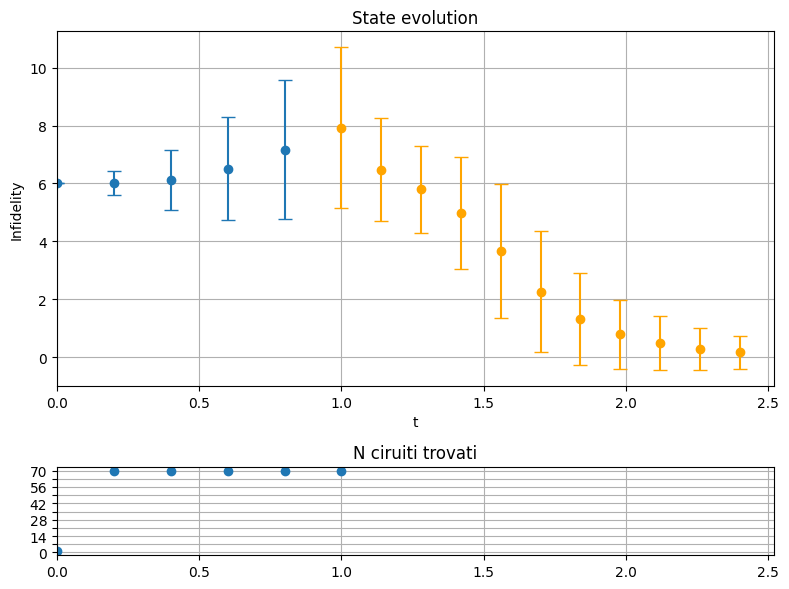

In [606]:
c1 = CircuitState.from_steps_ids([1,1,0],shape)
print("Start infidelity:", op.infidelity(c1))
d,i,c=op.simulate(c1,Nd=5,Ni=10,Td=1,Ti=1.4)

In [607]:
c2 = CircuitState.from_steps_ids([0,0,0],shape)
c2._state = c.copy()

CircuitState.equivalent(c1,c2.measure())
print(c1.draw())
print(c2.draw())

           
q_0: ──────
           
q_1: ──────
           
q_2: ─X──X─
      │  │ 
q_3: ─X──X─
           
     
q_0: 
     
q_1: 
     
q_2: 
     
q_3: 
     


Test dell'efficienza dei due diversi metodi di evoluzione

In [608]:
A = op.get_Hd(3,2)
v = CircuitState.from_steps_ids([0,1],shape)._state

In [609]:
# from scipy.sparse.linalg import expm_multiply
# import time

# X = []
# Y1 = []
# Y2 = []
# for n in range(1000,10000,1000):
#     num_timesteps = n
#     total_time = 1.0

#     start_time = time.time()
#     result_1 = expm_multiply(A, v, start=0, stop=total_time, num=num_timesteps)
#     time_method_1 = time.time() - start_time

#     start_time = time.time()
#     current_v = v
#     timestep = total_time / (num_timesteps - 1)
#     for i in range(1, num_timesteps):
#         current_v = expm_multiply(A, current_v, start=0, stop=timestep, num=2)[1]
#     time_method_2 = time.time() - start_time

#     X.append(n)
#     Y1.append(time_method_1)
#     Y2.append(time_method_2)

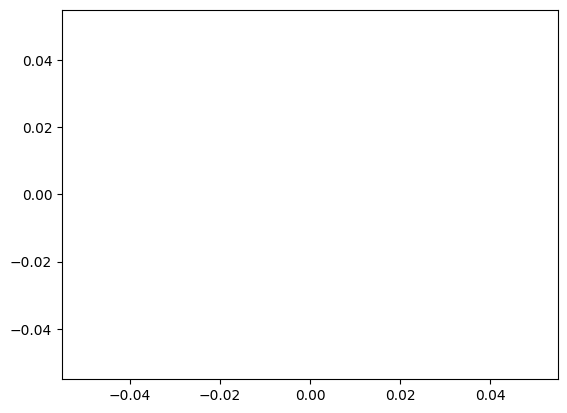

In [610]:
plt.plot(X,Y1,'o')
plt.plot(X,Y2,'o')